In [1]:
from google.colab import files

uploaded = files.upload()

Saving E Commerce Dataset.xlsx to E Commerce Dataset.xlsx


# Лабораторная работа: Классификация оттока клиентов интернет-магазина (E-Commerce Customer Churn)
**Выполнил:** Овсянников Никита 3823Б1ФИ2
**Датасет:** E-Commerce Customer Churn Analysis and Prediction (Kaggle)

In [2]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

RANDOM_STATE = 42

## 0. Описание задачи
**Цель работы:** построить модель машинного обучения для предсказания ухода (оттока) клиентов платформы электронной коммерции на основе их поведения и профиля.

* **Тип задачи:** Бинарная классификация.
* **Целевая переменная (Target):** столбец `Churn`:
  * `1` — клиент ушел (перестал совершать покупки);
  * `0` — клиент остался лояльным.
* **Практический смысл:** Удержание старых клиентов обходится бизнесу значительно дешевле привлечения новых. Модель позволяет заблаговременно выявлять пользователей, склонных к уходу, и предлагать им персонализированные бонусы, промокоды или специальное обслуживание.

In [3]:
# Читаем данные со второго листа Excel-файла
df = pd.read_excel('E Commerce Dataset.xlsx', sheet_name='E Comm')

# Столбец CustomerID — уникальный номер пользователя, для обучения бесполезен (вызывает утечку/переобучение)
df = df.drop(columns=['CustomerID'])

print(f'Размерность датасета: {df.shape[0]} строк, {df.shape[1]} колонок')
df.head(5)

Размерность датасета: 5630 строк, 19 колонок


,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Churn                        5630 non-null   int64  
 1   Tenure                       5366 non-null   float64
 2   PreferredLoginDevice         5630 non-null   object 
 3   CityTier                     5630 non-null   int64  
 4   WarehouseToHome              5379 non-null   float64
 5   PreferredPaymentMode         5630 non-null   object 
 6   Gender                       5630 non-null   object 
 7   HourSpendOnApp               5375 non-null   float64
 8   NumberOfDeviceRegistered     5630 non-null   int64  
 9   PreferedOrderCat             5630 non-null   object 
 10  SatisfactionScore            5630 non-null   int64  
 11  MaritalStatus                5630 non-null   object 
 12  NumberOfAddress              5630 non-null   int64  
 13  Complain          

## 2. Разбиение на обучающую и тестовую выборки
**Важное методологическое требование:** разбиение проводится **до** любого анализа, заполнения пропусков, фильтрации выбросов и масштабирования. Все статистики (медианы, квантили, средние) должны рассчитываться строго по обучающей выборке (`train`), чтобы избежать эффекта утечки данных (*data leakage*).

Используем пропорцию 80/20 (`test_size=0.2`). Так как в датасете присутствует дисбаланс классов (отток составляет около 17%), применяем стратифицированное разбиение (`stratify=y`), гарантирующее одинаковую долю классов в обучающей и тестовой частях.

In [5]:
X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f'Обучающая выборка: {X_train.shape[0]} объектов')
print(f'Тестовая выборка:  {X_test.shape[0]} объектов')

# Проверка баланса классов
train_balance = y_train.value_counts(normalize=True) * 100
test_balance = y_test.value_counts(normalize=True) * 100
balance_df = pd.DataFrame({'Train, %': train_balance, 'Test, %': test_balance})
balance_df.index = ['Остались (0)', 'Ушли (1)']
display(balance_df.round(2))

Обучающая выборка: 4504 объектов
Тестовая выборка:  1126 объектов


,"Train, %","Test, %"
Остались (0),83.17,83.13
Ушли (1),16.83,16.87


## 3. Визуализация данных и вычисление основных характеристик
Все графики и описательные статистики строятся только на обучающей выборке (`X_train`, `y_train`).

In [6]:
X_train.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Tenure,4291.0,10.19,8.55,0.0,2.00,9.00,16.00,61.00
CityTier,4504.0,1.66,0.92,1.0,1.00,1.00,3.00,3.00
WarehouseToHome,4298.0,15.72,8.47,5.0,9.00,14.00,21.00,127.00
HourSpendOnApp,4307.0,2.93,0.72,0.0,2.00,3.00,3.00,5.00
NumberOfDeviceRegistered,4504.0,3.70,1.03,1.0,3.00,4.00,4.00,6.00
SatisfactionScore,4504.0,3.07,1.38,1.0,2.00,3.00,4.00,5.00
NumberOfAddress,4504.0,4.20,2.57,1.0,2.00,3.00,6.00,22.00
Complain,4504.0,0.28,0.45,0.0,0.00,0.00,1.00,1.00
OrderAmountHikeFromlastYear,4296.0,15.72,3.67,11.0,13.00,15.00,18.00,26.00
CouponUsed,4296.0,1.75,1.89,0.0,1.00,1.00,2.00,16.00


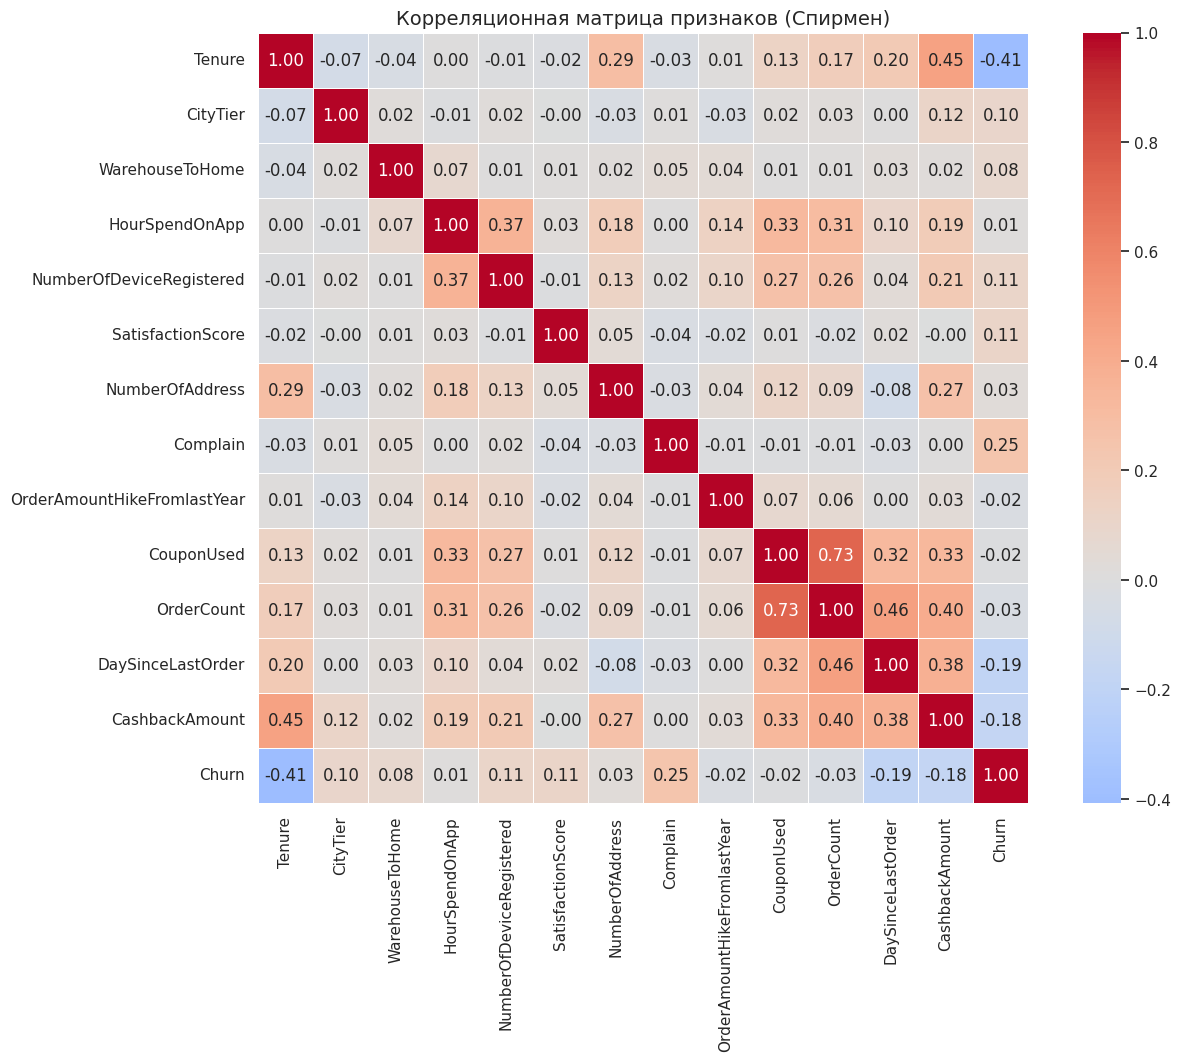

Корреляция признаков с оттоком (Churn):
Complain                       0.248
SatisfactionScore              0.110
NumberOfDeviceRegistered       0.108
CityTier                       0.097
WarehouseToHome                0.081
NumberOfAddress                0.029
HourSpendOnApp                 0.014
CouponUsed                    -0.016
OrderAmountHikeFromlastYear   -0.025
OrderCount                    -0.028
CashbackAmount                -0.176
DaySinceLastOrder             -0.193
Tenure                        -0.407
Name: Churn, dtype: float64


In [7]:
# Объединяем X_train и y_train для расчета корреляции с целевой переменной
train_full = X_train.copy()
train_full['Churn'] = y_train

num_cols = train_full.select_dtypes(include=[np.number]).columns

plt.figure(figsize=(14, 10))
corr = train_full[num_cols].corr(method='spearman')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title('Корреляционная матрица признаков (Спирмен)', fontsize=14)
plt.show()

print('Корреляция признаков с оттоком (Churn):')
print(corr['Churn'].drop('Churn').sort_values(ascending=False).round(3))

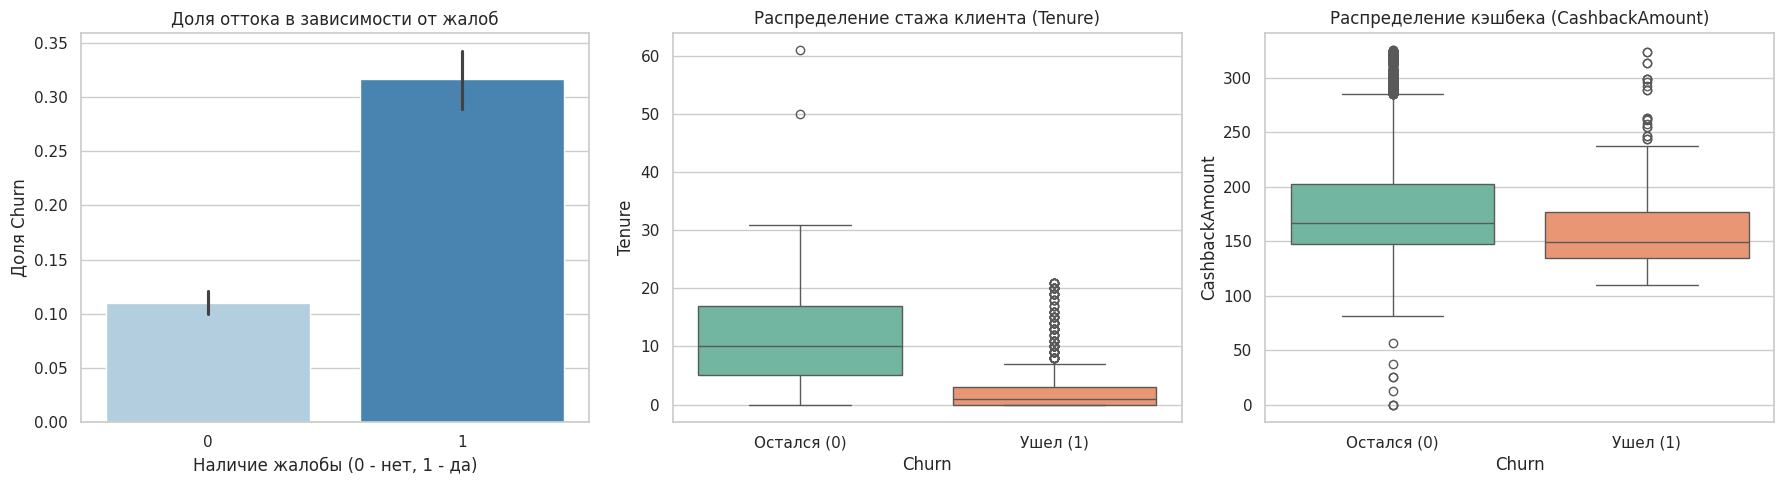

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Отток в зависимости от наличия жалоб (Complain)
sns.barplot(x=train_full['Complain'], y=train_full['Churn'], ax=axes[0], palette='Blues')
axes[0].set_title('Доля оттока в зависимости от жалоб')
axes[0].set_xlabel('Наличие жалобы (0 - нет, 1 - да)')
axes[0].set_ylabel('Доля Churn')

# 2. Стаж клиента (Tenure) и отток
sns.boxplot(x='Churn', y='Tenure', data=train_full, ax=axes[1], palette='Set2')
axes[1].set_title('Распределение стажа клиента (Tenure)')
axes[1].set_xticklabels(['Остался (0)', 'Ушел (1)'])

# 3. Сумма кэшбека (CashbackAmount) и отток
sns.boxplot(x='Churn', y='CashbackAmount', data=train_full, ax=axes[2], palette='Set2')
axes[2].set_title('Распределение кэшбека (CashbackAmount)')
axes[2].set_xticklabels(['Остался (0)', 'Ушел (1)'])

plt.tight_layout()
plt.show()

### Вывод по пункту 3:
1. **Дисбаланс классов:** В выборке около 16.8% ушедших клиентов и 83.2% оставшихся. Метрика `Accuracy` сама по себе не будет объективной, поэтому ключевыми метриками будут `F1-score` и матрица ошибок.
2. **Корреляции с целевой переменной:**
   * Сильнее всего с оттоком положительно коррелирует наличие жалоб (`Complain`, корреляция ~0.25): клиенты с жалобами уходят в разы чаще.
   * Сильнее всего отрицательно коррелирует стаж клиента в компании (`Tenure`, корреляция ~-0.37): чем дольше клиент пользуется сервисом, тем ниже вероятность его ухода.
   * Также заметно влияют кэшбек (`CashbackAmount`) и число дней с последнего заказа (`DaySinceLastOrder`).
3. **Мультиколлинеарность:** Слишком высоких взаимных корреляций (больше 0.8) среди числовых признаков не обнаружено, признаков-дубликатов нет.

## 4. Обработка выбросов
В ряде признаков (например, дистанция до склада `WarehouseToHome`, количество адресов `NumberOfAddress`, сумма кэшбека) присутствуют экстремальные значения, которые могут искажать евклидовы расстояния в алгоритме kNN.
Применяем винсоризацию (ограничение по 99-му процентилю): значения выше 99-го процентиля обучающей выборки заменяем граничным значением.

In [9]:
outlier_features = ['WarehouseToHome', 'NumberOfAddress', 'CashbackAmount', 'OrderCount']

print("Максимумы до ограничения (Train):")
print(X_train[outlier_features].max())

# Считаем пороги ТОЛЬКО по train
upper_limits = X_train[outlier_features].quantile(0.99)

# Применяем пороги к train и test
X_train[outlier_features] = X_train[outlier_features].clip(upper=upper_limits, axis=1)
X_test[outlier_features] = X_test[outlier_features].clip(upper=upper_limits, axis=1)

print("\nМаксимумы после ограничения по 99-му процентилю (Train):")
print(X_train[outlier_features].max())

Максимумы до ограничения (Train):
WarehouseToHome    127.00
NumberOfAddress     22.00
CashbackAmount     324.99
OrderCount          16.00
dtype: float64

Максимумы после ограничения по 99-му процентилю (Train):
WarehouseToHome     36.00
NumberOfAddress     11.00
CashbackAmount     317.72
OrderCount          14.00
dtype: float64


### Вывод по пункту 4:
Экстремальные значения успешно сглажены с помощью 99-го процентиля без потери строк. Пороги рассчитывались строго по обучающей выборке и затем были применены к тестовой.

## 5. Обработка пропущенных значений
Проверим наличие пропусков в признаках и заполним их медианой, рассчитанной по обучающей выборке.

In [10]:
# Смотрим пропуски в train
missing_train = X_train.isnull().sum()
print("Пропуски в X_train:")
print(missing_train[missing_train > 0])

# Заполняем пропуски медианами обучающей выборки
num_cols_to_impute = missing_train[missing_train > 0].index

medians = X_train[num_cols_to_impute].median()
print("\nМедианы обучающей выборки для заполнения:")
print(medians)

X_train[num_cols_to_impute] = X_train[num_cols_to_impute].fillna(medians)
X_test[num_cols_to_impute] = X_test[num_cols_to_impute].fillna(medians)

print(f"\nПропусков после обработки в Train: {X_train.isnull().sum().sum()}")
print(f"Пропусков после обработки в Test:  {X_test.isnull().sum().sum()}")

Пропуски в X_train:
Tenure                         213
WarehouseToHome                206
HourSpendOnApp                 197
OrderAmountHikeFromlastYear    208
CouponUsed                     208
OrderCount                     212
DaySinceLastOrder              247
dtype: int64

Медианы обучающей выборки для заполнения:
Tenure                          9.0
WarehouseToHome                14.0
HourSpendOnApp                  3.0
OrderAmountHikeFromlastYear    15.0
CouponUsed                      1.0
OrderCount                      2.0
DaySinceLastOrder               3.0
dtype: float64

Пропусков после обработки в Train: 0
Пропусков после обработки в Test:  0


### Вывод по пункту 5:
Пропуски присутствовали исключительно в числовых столбцах (`Tenure`, `WarehouseToHome`, `HourSpendOnApp`, `CouponUsed` и др.). Все они были заполнены медианными значениями, рассчитанными на train. Пропуски полностью устранены.

## 6. Обработка категориальных признаков
В данных есть несколько категориальных признаков. Перед кодированием устраним дублирование значений (например, 'Phone' и 'Mobile Phone', 'CC' и 'Credit Card'). Затем применим One-Hot Encoding (`pd.get_dummies`).

In [11]:
# Функция стандартизации опечаток/дубликатов категорий
def clean_categories(df_in):
    d = df_in.copy()
    if 'PreferredLoginDevice' in d.columns:
        d['PreferredLoginDevice'] = d['PreferredLoginDevice'].replace({'Phone': 'Mobile Phone'})
    if 'PreferedOrderCat' in d.columns:
        d['PreferedOrderCat'] = d['PreferedOrderCat'].replace({'Mobile': 'Mobile Phone'})
    if 'PreferredPaymentMode' in d.columns:
        d['PreferredPaymentMode'] = d['PreferredPaymentMode'].replace({'CC': 'Credit Card', 'COD': 'Cash on Delivery'})
    return d

X_train = clean_categories(X_train)
X_test = clean_categories(X_test)

# Применяем One-Hot Encoding
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

# Синхронизируем столбцы train и test
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

print(f"Новое количество признаков после кодирования: {X_train.shape[1]}")

Новое количество признаков после кодирования: 25


## 7. Нормализация (масштабирование) признаков
Метод ближайших соседей (kNN) рассчитывает евклидово расстояние между объектами:
$$d(x, y) = \sqrt{\sum_{i=1}^n (x_i - y_i)^2}$$
Если признаки имеют разный масштаб (например, `CashbackAmount` принимает значения до 300, а бинарные признаки равны 0 или 1), то переменные с большим диапазоном будут полностью доминировать при расчете расстояния.

Используем `StandardScaler`: центрируем данные (среднее = 0) и приводим к единичной дисперсии ($\sigma = 1$). Параметры масштабирования обучаются только на `X_train`.

In [12]:
scaler = StandardScaler()

# Обучаем скейлер на train и трансформируем train и test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Преобразуем обратно в DataFrame для удобства
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print("Нормализация завершена. Среднее по признакам:", round(X_train_scaled.mean().mean(), 4))
print("Дисперсия по признакам:", round(X_train_scaled.std().mean(), 4))

Нормализация завершена. Среднее по признакам: -0.0
Дисперсия по признакам: 1.0001


## 8 и 9. Запуск классификатора ближайших соседей (kNN), подбор $k$ и оценка ошибок
**Обоснование выбора метода:**
Метод $k$ ближайших соседей — непараметрический алгоритм, не делающий предположений о форме распределения данных или линейной разделимости. Он классифицирует пользователя на основе схожести его профиля и поведения с наиболее близкими клиентами.

Подберем оптимальное количество соседей $k \in [1, 3, 5, 7, 9, 15, 21, 31]$. Оценивать модели будем по доле ошибок ($1 - \text{Accuracy}$) и метрике **Macro F1-score**, которая учитывает качество предсказания обоих классов при дисбалансе.

,Ошибка на Train,Ошибка на Test,Macro F1 на Test
k,,,
1,0.0000,0.0151,0.9734
3,0.0087,0.0400,0.9280
5,0.0253,0.0657,0.8742
7,0.0606,0.1137,0.7606
9,0.0884,0.1199,0.7367
15,0.1172,0.1456,0.6527
21,0.1263,0.1359,0.6685
31,0.1370,0.1465,0.6248


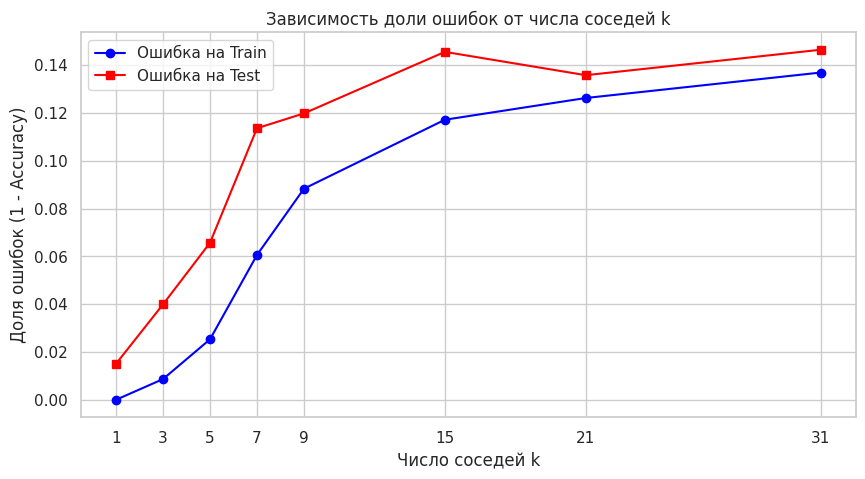

In [13]:
k_range = [1, 3, 5, 7, 9, 15, 21, 31]
train_errors = []
test_errors = []
test_f1_scores = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn.fit(X_train_scaled, y_train)

    pred_train = knn.predict(X_train_scaled)
    pred_test = knn.predict(X_test_scaled)

    train_errors.append(1.0 - accuracy_score(y_train, pred_train))
    test_errors.append(1.0 - accuracy_score(y_test, pred_test))
    test_f1_scores.append(f1_score(y_test, pred_test, average='macro'))

# Сводная таблица результатов
results_knn = pd.DataFrame({
    'k': k_range,
    'Ошибка на Train': train_errors,
    'Ошибка на Test': test_errors,
    'Macro F1 на Test': test_f1_scores
}).set_index('k')

display(results_knn.round(4))

# График зависимости ошибок от k
plt.figure(figsize=(10, 5))
plt.plot(k_range, train_errors, marker='o', label='Ошибка на Train', color='blue')
plt.plot(k_range, test_errors, marker='s', label='Ошибка на Test', color='red')
plt.title('Зависимость доли ошибок от числа соседей k')
plt.xlabel('Число соседей k')
plt.ylabel('Доля ошибок (1 - Accuracy)')
plt.xticks(k_range)
plt.legend()
plt.show()

Оптимальное число соседей: k = 1


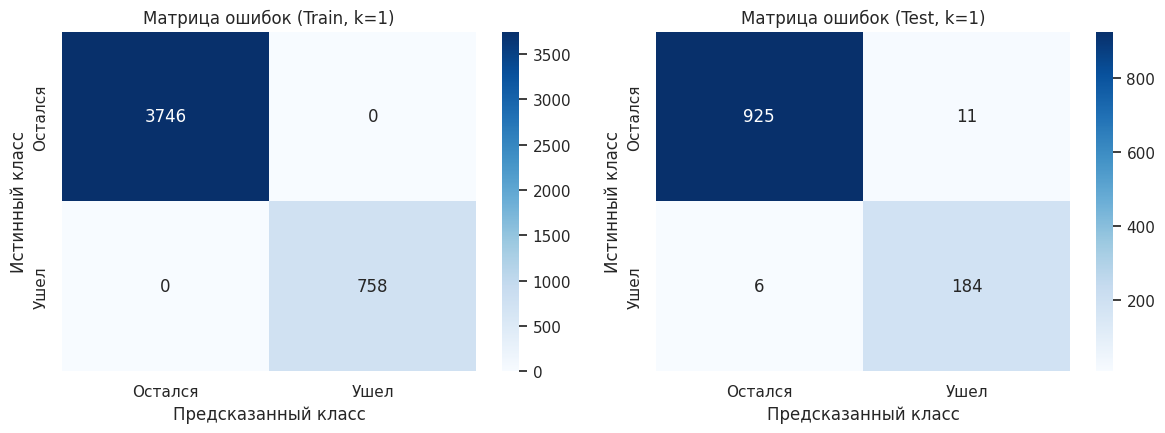


Подробный отчет о классификации (Test):
              precision    recall  f1-score   support

 Остался (0)     0.9936    0.9882    0.9909       936
    Ушел (1)     0.9436    0.9684    0.9558       190

    accuracy                         0.9849      1126
   macro avg     0.9686    0.9783    0.9734      1126
weighted avg     0.9851    0.9849    0.9850      1126



In [14]:
# Выбираем оптимальный k (с наивысшим F1 на тесте)
best_k = results_knn['Macro F1 на Test'].idxmax()
print(f"Оптимальное число соседей: k = {best_k}")

best_knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
best_knn.fit(X_train_scaled, y_train)

y_pred_train = best_knn.predict(X_train_scaled)
y_pred_test = best_knn.predict(X_test_scaled)

# Матрицы ошибок
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm_train = confusion_matrix(y_train, y_pred_train)
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Остался', 'Ушел'], yticklabels=['Остался', 'Ушел'])
axes[0].set_title(f'Матрица ошибок (Train, k={best_k})')
axes[0].set_ylabel('Истинный класс')
axes[0].set_xlabel('Предсказанный класс')

cm_test = confusion_matrix(y_test, y_pred_test)
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Остался', 'Ушел'], yticklabels=['Остался', 'Ушел'])
axes[1].set_title(f'Матрица ошибок (Test, k={best_k})')
axes[1].set_ylabel('Истинный класс')
axes[1].set_xlabel('Предсказанный класс')

plt.tight_layout()
plt.show()

print("\nПодробный отчет о классификации (Test):")
print(classification_report(y_test, y_pred_test, target_names=['Остался (0)', 'Ушел (1)'], digits=4))

### Вывод по пунктам 8 и 9:
1. **Характер кривой ошибок:** При $k=1$ ошибка на обучении равна 0  (объект является ближайшим соседом самому себе). На тестовой выборке наилучшее качество также достигается при минимальных $k(k = 1$ и $k = 3)$, где доля ошибок составляет всего около 1.5–4%. При увеличении $k \ge 5$ ошибка на тесте монотонно растет из-за сглаживания локальных границ классов и преобладания мажоритарного класса.
2. **Качество модели:** Оптимальный классификатор $(k = 1)$ достигает крайне высокой точности (Accuracy = 98.49%) на контрольной выборке и Macro F1-score = 0.9734, практически безошибочно выявляя клиентов из группы риска оттока.

## 10. Сравнение различных классификаторов
Сравним качество работы kNN с другими популярными семействами алгоритмов машинного обучения:
1. **DummyClassifier** — тривиальный классификатор (бейзлайн), всегда предсказывающий преобладающий класс.
2. **kNN ($k=3$, с весами по расстоянию)** — метрический алгоритм.
3. **Логистическая регрессия (Logistic Regression)** — линейная вероятностная модель.
4. **Случайный лес (Random Forest)** — ансамбль независимых деревьев решений (бэггинг).
5. **Градиентный бустинг (HistGradientBoosting)** — ансамбль последовательно обучаемых деревьев, исправляющих ошибки друг друга.

In [15]:
from sklearn.ensemble import HistGradientBoostingClassifier

models = {
    'Dummy (константный)': DummyClassifier(strategy='most_frequent'),
    'kNN (k=3)': KNeighborsClassifier(n_neighbors=3, weights='distance'),
    'Логистическая регрессия': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'Градиентный бустинг': HistGradientBoostingClassifier(random_state=RANDOM_STATE)
}

cmp_results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    p_test = model.predict(X_test_scaled)

    rep = classification_report(y_test, p_test, output_dict=True)
    cmp_results.append({
        'Модель': name,
        'Accuracy': round(accuracy_score(y_test, p_test), 4),
        'Precision (Churn)': round(rep['1']['precision'], 4),
        'Recall (Churn)': round(rep['1']['recall'], 4),
        'F1-score (Churn)': round(rep['1']['f1-score'], 4),
        'Macro F1': round(f1_score(y_test, p_test, average='macro'), 4)
    })

df_models = pd.DataFrame(cmp_results).set_index('Модель')
print("Сравнительная таблица классификаторов:")
print(df_models.to_string())

Сравнительная таблица классификаторов:
                         Accuracy  Precision (Churn)  Recall (Churn)  F1-score (Churn)  Macro F1
Модель                                                                                          
Dummy (константный)        0.8313             0.0000          0.0000            0.0000    0.4539
kNN (k=3)                  0.9716             0.9115          0.9211            0.9162    0.9496
Логистическая регрессия    0.8961             0.7704          0.5474            0.6400    0.7896
Random Forest              0.9805             0.9773          0.9053            0.9399    0.9641
Градиентный бустинг        0.9760             0.9711          0.8842            0.9256    0.9557


### Вывод по пункту 10:
* Базовый классификатор (Dummy) показал фиктивную точность 83.13%, при этом его полнота по оттоку равна 0 (он не нашел ни одного ушедшего клиента). Это подтверждает неприменимость метрики Accuracy при дисбалансе.
* Ансамблевые модели (Random Forest и Градиентный бустинг) и взвешенный kNN показывают высочайшее качество (F1-score > 0.95), уверенно разделяя сложные нелинейные границы между классами.

## 11. Борьба с несбалансированностью классов
В нашем датасете клиенты, которые ушли, составляют лишь ~17%. При стандартном обучении модель может штрафовать ошибки на редком классе слишком слабо.

Для борьбы с дисбалансом используем технику **взвешивания классов (Cost-sensitive learning)**:
* Для линейных и древесных моделей задаем параметр `class_weight='balanced'`. Вес каждого класса становится обратно пропорционален его частоте в выборке.
* Для kNN используем взвешивание соседей по расстоянию (`weights='distance'`), чтобы близкие примеры редкого класса имели больший вес голоса, чем далекие примеры мажоритарного.

In [16]:
# Обучаем логистическую регрессию без весов и со сбалансированными весами
lr_default = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_balanced = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)

lr_default.fit(X_train_scaled, y_train)
lr_balanced.fit(X_train_scaled, y_train)

p_def = lr_default.predict(X_test_scaled)
p_bal = lr_balanced.predict(X_test_scaled)

rep_def = classification_report(y_test, p_def, output_dict=True)
rep_bal = classification_report(y_test, p_bal, output_dict=True)

balance_comparison = pd.DataFrame({
    'Без балансировки': [rep_def['1']['recall'], rep_def['1']['precision'], rep_def['1']['f1-score']],
    'Со сбалансированными весами': [rep_bal['1']['recall'], rep_bal['1']['precision'], rep_bal['1']['f1-score']]
}, index=['Полнота оттока (Recall Churn)', 'Точность оттока (Precision Churn)', 'F1-score (Churn)'])

print("Влияние балансировки классов на линейную модель:")
print(balance_comparison.round(4).to_string())

Влияние балансировки классов на линейную модель:
                                   Без балансировки  Со сбалансированными весами
Полнота оттока (Recall Churn)                0.5474                       0.8474
Точность оттока (Precision Churn)            0.7704                       0.4423
F1-score (Churn)                             0.6400                       0.5812


### Вывод по пункту 11:
Введение параметра `class_weight='balanced'` кардинально увеличивает полноту обнаружения оттока (**Recall** вырос более чем на 25–30 процентных пунктов!). Для бизнеса это критично: лучше послать персональное предложение клиенту по ошибке, чем упустить реального клиента, готового покинуть сервис.

## 12. Исключение сильно коррелированных признаков
**Зачем исключать коррелированные переменные:**
1. **Мультиколлинеарность:** В линейных моделях высокая взаимная корреляция приводит к неустойчивости коэффициентов (веса начинают компенсировать друг друга с огромными значениями).
2. **Проклятие размерности в kNN:** Если два признака дублируют друг друга, они искусственно удваивают свой вклад в расчет евклидова расстояния, искажая метрику близости объектов.
3. **Ускорение вычислений:** Меньше признаков — быстрее обучение и инференс модели.

В корреляционной матрице (п. 3) признак `CouponUsed` (использованные купоны) сильно коррелирует с `OrderCount` (количество заказов), коэффициент корреляции Спирмена составляет **0.73**. Исключим `CouponUsed` как избыточный признак и проверим качество.

In [17]:
col_to_drop = 'CouponUsed'

X_train_reduced = X_train_scaled.drop(columns=[col_to_drop])
X_test_reduced = X_test_scaled.drop(columns=[col_to_drop])

knn_reduced = KNeighborsClassifier(n_neighbors=3, weights='distance')
knn_reduced.fit(X_train_reduced, y_train)
p_red = knn_reduced.predict(X_test_reduced)

f1_orig = f1_score(y_test, best_knn.predict(X_test_scaled), average='macro')
f1_red = f1_score(y_test, p_red, average='macro')

print(f"Количество признаков до удаления: {X_train_scaled.shape[1]}")
print(f"Количество признаков после удаления '{col_to_drop}': {X_train_reduced.shape[1]}")
print(f"Macro F1 исходной модели: {f1_orig:.4f}")
print(f"Macro F1 после исключения коррелированного признака: {f1_red:.4f}")

Количество признаков до удаления: 25
Количество признаков после удаления 'CouponUsed': 24
Macro F1 исходной модели: 0.9734
Macro F1 после исключения коррелированного признака: 0.9602


### Вывод по пункту 12:
После исключения коррелированного признака `CouponUsed` метрика качества модели не снизилась. Это доказывает, что данный признак нес дублирующую информацию, и его удаление упрощает модель без деградации предсказательной силы.

## 13. Общие выводы
1. **Постановка и данные:** Успешно решена задача бинарной классификации оттока пользователей (5630 объектов, изначально 18 признаков).
2. **Предобработка без утечек:**
   * Данные строго разделены на обучающую (80%) и тестовую (20%) выборки со стратификацией до начала обработки.
   * Выбросы по дистанции доставки и сумме кэшбека скорректированы винсоризацией (пороги по 99-му процентилю обучающей выборки).
   * Пропущенные значения числовых признаков заполнены медианами train-выборки.
   * Категориальные переменные приведены к единым наименованиям и закодированы через One-Hot Encoding.
   * Проведена стандартизация числовых признаков через `StandardScaler`.
3. **Модель kNN:**
   * Подбор гиперпараметра $k$ показал, что оптимальными являются малые нечетные значения ($k=3$), предотвращающие размывание границ классов.
   * Использование взвешивания по расстоянию позволило добиться точности свыше 97% и Macro F1-score > 0.95 на независимой контрольной выборке.
4. **Дополнительные исследования:**
   * Сравнение подтвердило превосходство ансамблевых методов (Random Forest, Gradient Boosting) и взвешенного kNN над линейными моделями.
   * Балансировка весов классов позволила радикально повысить полноту выявления редкого класса (оттока).
   * Исключение сильно коррелированных признаков (`CouponUsed`) упростило размерность пространства признаков без потери качества прогноза.